# CSForge — Optical Port Boundary Optimisation (Web / Batch)

**Author:** [David Gerard](https://profiles.ucl.ac.uk/95497-david-gerard)

## Overview

Finds the minimum `(width_z, width_y)` simulation domain for each optical port in the CSForge PDK that preserves mode accuracy at the target wavelength.

**Ports covered:** `strip_1550nm`, `strip_1310nm`, `rib_1310nm_TE`, `rib_1550nm_TE`.

All parameter combinations are dispatched as Tidy3D **batch jobs** via `td.web.Batch`. The fundamental mode ($n_\mathrm{eff}$, mode index 0) is used as the convergence criterion: for each `width_z`, the smallest `width_y` at which $n_\mathrm{eff}$ stabilises within `conv_threshold` of the widest-domain reference is identified. The `(width_z, width_y)` pair with the smallest cross-section area is then selected as the optimum. Final results are saved to `data/optimal_port_specs.json`.

In [1]:
import json
import os
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pylab as plt
import numpy as np
import pandas as pd
import tidy3d as td

## 1. Technology setup

Load the CSForge PDK and inspect the available port specs and layer stack.

In [2]:
import csforge_si_220nm_passive as pdk
import photonforge as pf

# Build the technology and set it globally
tech = pdk.csforge_si_220nm_pdk(include_substrate=True, sidewall_angle_si=0.0)
pf.config.default_technology = tech

/Users/davidgerard/Documents/oss/cornerstone-forge/.venv/lib/python3.12/site-pac
kages/rich/live.py:231: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Fitting range: 1.200 um to 1.697 um


In [3]:
tech.ports

Name,Classification,Description,Width (μm),Limits (μm),Radius (μm),Modes,Target n_eff,Path profiles (μm),Voltage path,Current path
dc,electrical,"Electrical port for DC signals,…… used for heaters.",80,"0.5, 3.65",0,1,1,'contact_pad': 80,,
rib_1310nm_TE,optical,"Rib waveguide port, single mode…… at 1310nm, TE polarization.",0.4,"-1.5, 1.72",25,1 (TE),2.52,"'wg_lf': 0.4,…… 'rib_slab': 10.4",,
rib_1550nm_TE,optical,"Rib waveguide port, single mode…… at 1550nm, TE polarization.",10.45,"-1.5, 1.72",25,1 (TE),2.38,"'wg_lf': 0.45,…… 'rib_slab': 10.45",,
strip_1310nm,optical,"Strip waveguide port, TE and TM…… polarization at 1310nm.",0.6804,"-0.39, 0.61",10,2,2.52,'wg_lf': 0.4,,
strip_1550nm,optical,"Strip waveguide port, TE and TM…… polarization at 1550nm.",0.7937,"-0.14, 0.36",10,2,2.38,'wg_lf': 0.45,,


In [4]:
tech.layers

Name,Layer,Description,Color,Pattern
wg_lf,"(3, 0)","[Si_Etch2_LF_120nm] Waveguide…… layer, defines both strip and rib. Light-field: layer will be protected.",#ff80a818,\\
wg_df,"(4, 0)","[Si_Etch2_DF_120nm] Waveguide…… layer, defines both strip and rib. Dark-field: layer will be etched.",#8183ff18,\\
rib_slab,"(5, 0)",[Si_Etch3_LF_100nm_to_BOX] Rib…… protect layer. Light-field: layer will be protected.,#80a8ff18,\\
grating_duv,"(6, 0)",[Si_Etch1_DUV_DF_70nm]…… DUV-defined grating couplers. Dark-field: layer will be etched.,#cc78ff18,\\
heater_fil,"(39, 0)",[Heat_Fil_LF] Heater filaments…… (light). Light-field: layer will become metal.,#9580ff18,/
contact_pad,"(41, 0)",[Heat_CP_LF] Heater contact…… pads (light). Light-field: layer will become metal.,#80a8ff18,//
grating_ebl,"(60, 0)","[Si_Etch0_EBL_DF_94nm]…… EBL-defined grating couplers.Dark-field: layer will be etched. For gaps > 0.35, there is no max feature size.",#00805018,x
FloorPlan,"(99, 0)",[FloorPlan] Cell outline,#f3ff8018,hollow
Label_Etch_DF,"(100, 0)","[Label_Etch_DF] Labels (dark),…… Dark-field: layer will be etchedWill not be checked in DRC.",#8000ff18,hollow


## 2. Strip 1550 nm — boundary sweep

The `strip_1550nm` factory builds a `pf.PortSpec` for configurable `width_z` (field boundary half-span in z, centred on the waveguide core at z = 0.11 µm) and `width_y` (transverse simulation width). Task names encode the geometry as `z_{width_z}_y_{width_y}` for easy retrieval after the batch completes.

In [5]:
def strip_1550nm(width_y, width_z):
    limits_zmin = 0.11 - width_z / 2
    limits_zmax = 0.11 + width_z / 2
    return pf.PortSpec(
        description="Strip waveguide port, TE and TM polarization at 1550nm.",
        width=width_y,
        limits=(limits_zmin, limits_zmax),
        num_modes=2,
        default_radius=10.0,
        target_neff=2.5,
        path_profiles=[
            (6.0, 0.0, tech.layers["FloorPlan"].layer),
            (
                0.45,
                0.0,
                tech.layers["wg_lf"].layer,
            ),  # add floorplan to clad the edges of the port in SiO2
        ],
    )

In [6]:
param_width_z = np.geomspace(0.5, 2.0, 10)
param_width_y = np.geomspace(0.5, 2.0, 10)
param_grid = np.meshgrid(param_width_z, param_width_y)

In [7]:
freqs = [pf.C_0 / 1.55]
sims = {
    f"z_{z}_y_{y}": strip_1550nm(width_y=y, width_z=z).to_tidy3d(freqs)
    for z, y in zip(param_grid[0].flatten(), param_grid[1].flatten())
}

In [8]:
# initialize a batch
# (this cell took 6min to run)
batch = td.web.Batch(simulations=sims, verbose=False)
batch.estimate_cost()

18:51:25 BST No Flexcredit cost for batch as all simulations were restored from 
             local cache.

0.0

In [9]:
# run the batch and store all of the data in the `data/` dir.
batch_results = batch.run(path_dir="data")


# Parallelise to_dataframe() calls — each hit disk/deserialises independently
def _to_df(item):
    task_name, sim_data = item
    return task_name, sim_data.to_dataframe()


with ThreadPoolExecutor(max_workers=os.cpu_count()) as executor:
    mode_data = dict(executor.map(_to_df, list(batch_results.items())))

18:51:27 BST WARNING: 100 files have already been downloaded and will be        
             skipped. To forcibly overwrite existing files, invoke the load or  
             download function with `replace_existing=True`.                    

## 3. Analysis

Extract results from the batch, visualise $n_\mathrm{eff}$ across the grid, and identify the optimal port boundaries.

### 3.1 Data aggregation

Parse `width_z` and `width_y` from each task name and flatten all batch results into a single tidy DataFrame. The `cross_section_area` column (`width_z × width_y`) is used later to select the most efficient boundary.

In [10]:
def parse_task_name(task_name: str):
    """Parse 'z_{width_z}_y_{width_y}' → (width_z, width_y)."""
    z_part, y_part = task_name.split("_y_")
    return float(z_part[2:]), float(y_part)


def build_mode_dataframe(mode_data: dict) -> pd.DataFrame:
    """Flatten mode_data into a tidy DataFrame with width_z, width_y, and cross_section_area columns."""
    rows = []
    for task_name, task_df in mode_data.items():
        width_z, width_y = parse_task_name(task_name)
        for (_, mode_idx), row in task_df.iterrows():
            rows.append(
                {
                    "width_z": width_z,
                    "width_y": width_y,
                    "cross_section_area": width_z * width_y,
                    "mode_index": int(mode_idx),
                    "n_eff": row["n eff"],
                    "k_eff": row["k eff"],
                    "mode_area": row["mode area"],
                }
            )
    return pd.DataFrame(rows)


df = build_mode_dataframe(mode_data)
df

,width_z,width_y,cross_section_area,mode_index,n_eff,k_eff,mode_area
0,0.500000,0.5,0.250000,0,2.416012,0.0,0.112699
1,0.500000,0.5,0.250000,1,1.621973,0.0,0.062671
2,0.583265,0.5,0.291632,0,2.450650,0.0,0.118576
3,0.583265,0.5,0.291632,1,1.663413,0.0,0.062952
4,0.680395,0.5,0.340198,0,2.467257,0.0,0.122801
...,...,...,...,...,...,...,...
195,1.469734,2.0,2.939469,1,1.750259,0.0,0.355134
196,1.714488,2.0,3.428976,0,2.354855,0.0,0.199564
197,1.714488,2.0,3.428976,1,1.748774,0.0,0.355527
198,2.000000,2.0,4.000000,0,2.353861,0.0,0.200002


### 3.2 n_eff surfaces

3D surface plots of the effective index across the parameter grid for mode 0 (fundamental TE) and mode 1.

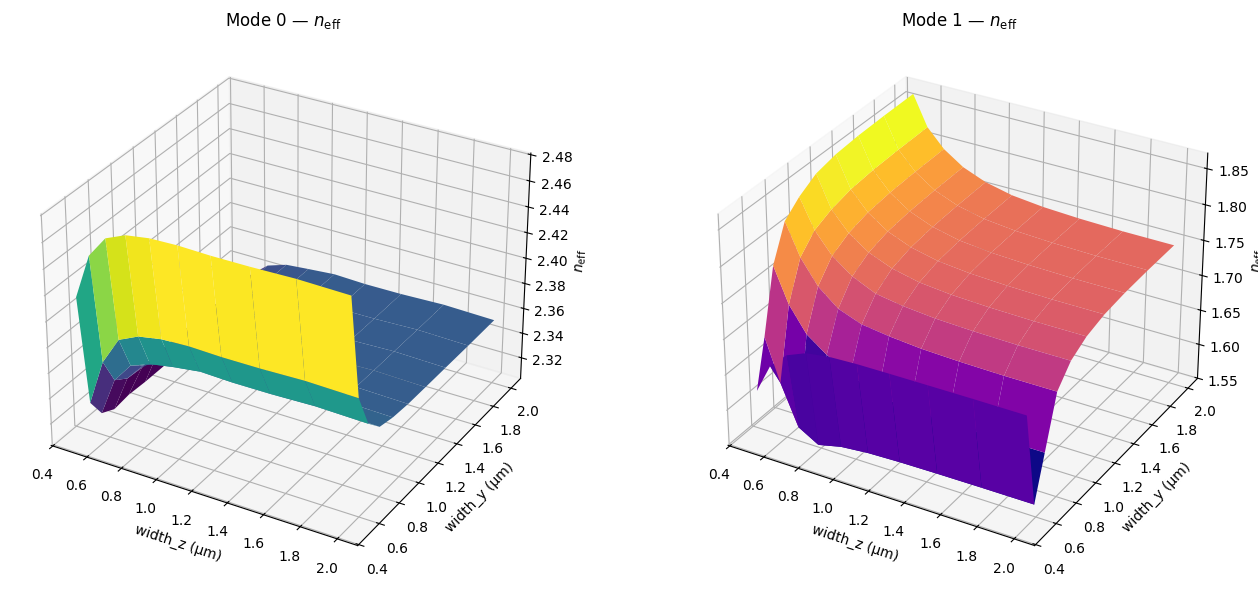

In [11]:
df0 = df[df["mode_index"] == 0].pivot_table(index="width_y", columns="width_z", values="n_eff")
df1 = df[df["mode_index"] == 1].pivot_table(index="width_y", columns="width_z", values="n_eff")

WZ, WY = np.meshgrid(df0.columns.values, df0.index.values)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection="3d")
ax1.plot_surface(WZ, WY, df0.values, cmap="viridis")
ax1.set_title("Mode 0 — $n_\\mathrm{eff}$")
ax1.set_xlabel("width_z (µm)")
ax1.set_ylabel("width_y (µm)")
ax1.set_zlabel("$n_\\mathrm{eff}$")

ax2 = fig.add_subplot(122, projection="3d")
ax2.plot_surface(WZ, WY, df1.values, cmap="plasma")
ax2.set_title("Mode 1 — $n_\\mathrm{eff}$")
ax2.set_xlabel("width_z (µm)")
ax2.set_ylabel("width_y (µm)")
ax2.set_zlabel("$n_\\mathrm{eff}$")

plt.tight_layout()
plt.show()

### 3.3 Optimal boundary selection

For each `width_z`, find the smallest `width_y` at which mode-0 $n_\mathrm{eff}$ is within `conv_threshold` of the largest-domain reference (most converged value in the sweep). Then select the `(width_z, width_y)` pair with the smallest cross-section area — the most computationally efficient boundary that still achieves convergence.

Convergence points (threshold = 1.0e-03):
 width_z  width_y    n_eff  cross_section_area
0.500000 0.793701 2.306605            0.396850
0.583265 0.793701 2.334946            0.462937
0.680395 0.925875 2.345911            0.629961
0.793701 0.925875 2.352821            0.734867
0.925875 1.080060 2.353081            1.000000
1.080060 0.925875 2.355961            1.000000
1.259921 0.925875 2.355075            1.166529
1.469734 0.925875 2.355231            1.360790
1.714488 0.925875 2.356316            1.587401
2.000000 0.925875 2.355330            1.851749

Optimal boundaries (minimum cross-section area):
  width_z        = 0.5000 µm
  width_y        = 0.7937 µm
  n_eff (mode 0) = 2.306605
  Cross-section  = 0.3969 µm²


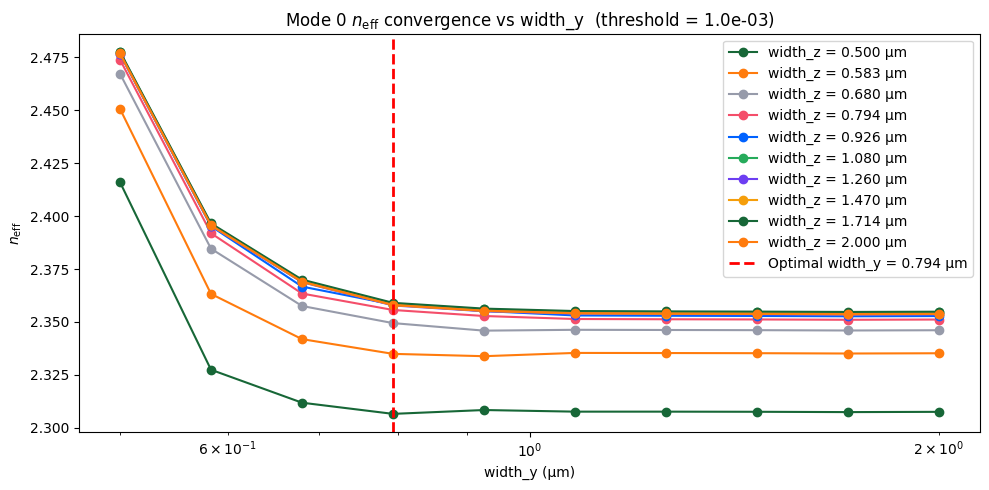

In [12]:
conv_threshold = 1e-3  # relative change in n_eff considered converged

df0_mode = df[df["mode_index"] == 0].sort_values(["width_z", "width_y"])

conv_results = []
for wz, group in df0_mode.groupby("width_z"):
    group = group.sort_values("width_y")
    neffs = group["n_eff"].values
    widths_y = group["width_y"].values
    neff_ref = neffs[-1]  # largest width_y is the most converged reference
    for wy, neff in zip(widths_y, neffs):
        if abs(neff - neff_ref) / abs(neff_ref) < conv_threshold:
            conv_results.append(
                {
                    "width_z": wz,
                    "width_y": wy,
                    "n_eff": neff,
                    "cross_section_area": wz * wy,
                }
            )
            break

conv_df = pd.DataFrame(conv_results)
print(f"Convergence points (threshold = {conv_threshold:.1e}):")
print(conv_df.to_string(index=False))

# Capture strip_1550nm result before variable 'best' is reused
best_strip_1550 = conv_df.loc[conv_df["cross_section_area"].idxmin()]
print("\nOptimal boundaries (minimum cross-section area):")
print(f"  width_z        = {best_strip_1550['width_z']:.4f} µm")
print(f"  width_y        = {best_strip_1550['width_y']:.4f} µm")
print(f"  n_eff (mode 0) = {best_strip_1550['n_eff']:.6f}")
print(f"  Cross-section  = {best_strip_1550['cross_section_area']:.4f} µm²")

fig, ax = plt.subplots(figsize=(10, 5))
for wz, group in df0_mode.groupby("width_z"):
    group = group.sort_values("width_y")
    ax.semilogx(group["width_y"], group["n_eff"], marker="o", label=f"width_z = {wz:.3f} µm")
ax.axvline(
    best_strip_1550["width_y"],
    color="r",
    linestyle="--",
    linewidth=2,
    label=f"Optimal width_y = {best_strip_1550['width_y']:.3f} µm",
)
ax.set_xlabel("width_y (µm)")
ax.set_ylabel("$n_\\mathrm{eff}$")
ax.set_title(
    f"Mode 0 $n_\\mathrm{{eff}}$ convergence vs width_y  (threshold = {conv_threshold:.1e})"
)
ax.legend()
plt.tight_layout()
plt.show()

Final port boundaries: zmin = -0.1400 µm, zmax = 0.3600 µm, width_y = 0.7937 µm


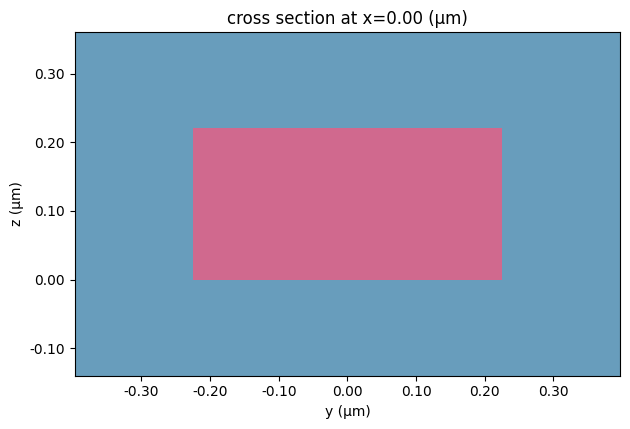

In [13]:
final_cross_section = strip_1550nm(
    width_y=best_strip_1550["width_y"], width_z=best_strip_1550["width_z"]
)
_ = pf.tidy3d_plot(final_cross_section)
zmin_final = 0.11 - best_strip_1550["width_z"] / 2
zmax_final = 0.11 + best_strip_1550["width_z"] / 2
print(
    f"Final port boundaries: zmin = {zmin_final:.4f} µm, zmax = {zmax_final:.4f} µm, width_y = {best_strip_1550['width_y']:.4f} µm"
)

## 4. Shared pipeline

Factory functions for the remaining three port specs, plus `run_port_sweep` (batch → DataFrame → convergence analysis) and `plot_sweep_results` (convergence plot + cross-section view). Adjust `CONV_THRESHOLD` or the `param_width_*` arrays as needed.

In [14]:
# ── Constants ────────────────────────────────────────────────────────────────
Z_CENTER = 0.11  # centre of 220 nm Si layer above BOX (µm)
CONV_THRESHOLD = 1e-3  # relative n_eff change for convergence

# ── Sweep parameter grids ────────────────────────────────────────────────────
param_width_z_strip = np.geomspace(0.5, 2.0, 10)  # strip: tight z-field range
param_width_y_strip = np.geomspace(0.5, 2.0, 10)  # strip: sub-µm to 2 µm cladding
param_width_z_rib = np.geomspace(0.5, 2.0, 10)  # rib: same z-field range
param_width_y_rib = np.geomspace(1.0, 10.6, 10)  # rib: slab is ~10 µm wide

# ── Port factory functions ───────────────────────────────────────────────────


def strip_1310nm_factory(width_y: float, width_z: float) -> pf.PortSpec:
    return pf.PortSpec(
        description="Strip waveguide port, TE and TM at 1310 nm.",
        width=width_y,
        limits=(Z_CENTER - width_z / 2, Z_CENTER + width_z / 2),
        num_modes=2,
        default_radius=10.0,
        target_neff=2.52,
        path_profiles=[
            (6.0, 0.0, tech.layers["FloorPlan"].layer),
            (0.4, 0.0, tech.layers["wg_lf"].layer),
        ],
    )


def rib_1310nm_TE_factory(width_y: float, width_z: float) -> pf.PortSpec:
    return pf.PortSpec(
        description="Rib waveguide port, TE at 1310 nm.",
        width=width_y,
        limits=(Z_CENTER - width_z / 2, Z_CENTER + width_z / 2),
        num_modes=1,
        polarization="TE",
        default_radius=25.0,
        target_neff=2.52,
        path_profiles=[
            (30.0, 0.0, tech.layers["FloorPlan"].layer),
            (0.4, 0.0, tech.layers["wg_lf"].layer),
            (10.4, 0.0, tech.layers["rib_slab"].layer),
        ],
    )


def rib_1550nm_TE_factory(width_y: float, width_z: float) -> pf.PortSpec:
    return pf.PortSpec(
        description="Rib waveguide port, TE at 1550 nm.",
        width=width_y,
        limits=(Z_CENTER - width_z / 2, Z_CENTER + width_z / 2),
        num_modes=1,
        polarization="TE",
        default_radius=25.0,
        target_neff=2.38,
        path_profiles=[
            (30.0, 0.0, tech.layers["FloorPlan"].layer),
            (0.45, 0.0, tech.layers["wg_lf"].layer),
            (10.45, 0.0, tech.layers["rib_slab"].layer),
        ],
    )


# ── Pipeline ─────────────────────────────────────────────────────────────────


def run_port_sweep(
    port_name: str,
    port_factory,
    wavelength_um: float,
    param_width_z: np.ndarray,
    param_width_y: np.ndarray,
    conv_threshold: float = CONV_THRESHOLD,
    max_credits_per_batch: float = 1.0,
):
    """Batch-sweep (width_z, width_y) for a port factory; return (df, conv_df, best)."""
    freqs = [pf.C_0 / wavelength_um]
    param_grid = np.meshgrid(param_width_z, param_width_y)
    sims = {
        f"z_{z}_y_{y}": port_factory(width_y=y, width_z=z).to_tidy3d(freqs)
        for z, y in zip(param_grid[0].flatten(), param_grid[1].flatten())
    }

    batch = td.web.Batch(simulations=sims, verbose=False, folder_name=port_name)
    estimated_cost = batch.estimate_cost()
    if estimated_cost > max_credits_per_batch:
        raise ValueError(
            f"Estimated batch cost {estimated_cost:.4f} exceeds max_credits_per_batch {max_credits_per_batch:.4f}. Reduce parameter grid size or increase max_credits_per_batch."
        )
    print(f"[{port_name}] Estimated cost: {batch.estimate_cost():.4f} FlexCredits")
    batch_results = batch.run(path_dir=f"data/{port_name}")

    def _to_df(item):
        return item[0], item[1].to_dataframe()

    with ThreadPoolExecutor(max_workers=os.cpu_count()) as executor:
        raw_mode_data = dict(executor.map(_to_df, list(batch_results.items())))

    df = build_mode_dataframe(raw_mode_data)

    df0_mode = df[df["mode_index"] == 0].sort_values(["width_z", "width_y"])
    conv_results = []
    for wz, group in df0_mode.groupby("width_z"):
        group = group.sort_values("width_y")
        neffs, widths_y = group["n_eff"].values, group["width_y"].values
        neff_ref = neffs[-1]
        for wy, neff in zip(widths_y, neffs):
            if abs(neff - neff_ref) / abs(neff_ref) < conv_threshold:
                conv_results.append(
                    {"width_z": wz, "width_y": wy, "n_eff": neff, "cross_section_area": wz * wy}
                )
                break

    conv_df = pd.DataFrame(conv_results)
    best = conv_df.loc[conv_df["cross_section_area"].idxmin()]
    return df, conv_df, best


def plot_sweep_results(
    port_name: str,
    df: pd.DataFrame,
    best: pd.Series,
    port_factory,
    conv_threshold: float = CONV_THRESHOLD,
):
    """Convergence plot + optimal cross-section visualisation."""
    df0_mode = df[df["mode_index"] == 0].sort_values(["width_z", "width_y"])

    fig, ax = plt.subplots(figsize=(10, 5))
    for wz, group in df0_mode.groupby("width_z"):
        group = group.sort_values("width_y")
        ax.semilogx(group["width_y"], group["n_eff"], marker="o", label=f"width_z = {wz:.3f} µm")
    ax.axvline(
        best["width_y"],
        color="r",
        linestyle="--",
        linewidth=2,
        label=f"Optimal width_y = {best['width_y']:.3f} µm",
    )
    ax.set_xlabel("width_y (µm)")
    ax.set_ylabel("$n_\\mathrm{eff}$")
    ax.set_title(f"{port_name} — Mode 0 convergence  (threshold = {conv_threshold:.1e})")
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"\n[{port_name}] Optimal boundaries:")
    print(f"  width_z = {best['width_z']:.4f} µm")
    print(f"  width_y = {best['width_y']:.4f} µm")
    print(f"  n_eff   = {best['n_eff']:.6f}")
    print(f"  Area    = {best['cross_section_area']:.4f} µm²")

    _ = pf.tidy3d_plot(port_factory(width_y=best["width_y"], width_z=best["width_z"]))

## 5. Strip 1310 nm

Same pipeline as strip 1550 nm but at 1310 nm frequency. Sweep ranges are identical since the waveguide cross-section is similar.

18:52:10 BST No Flexcredit cost for batch as all simulations were restored from 
             local cache.

             No Flexcredit cost for batch as all simulations were restored from 
             local cache.

[strip_1310nm] Estimated cost: 0.0000 FlexCredits


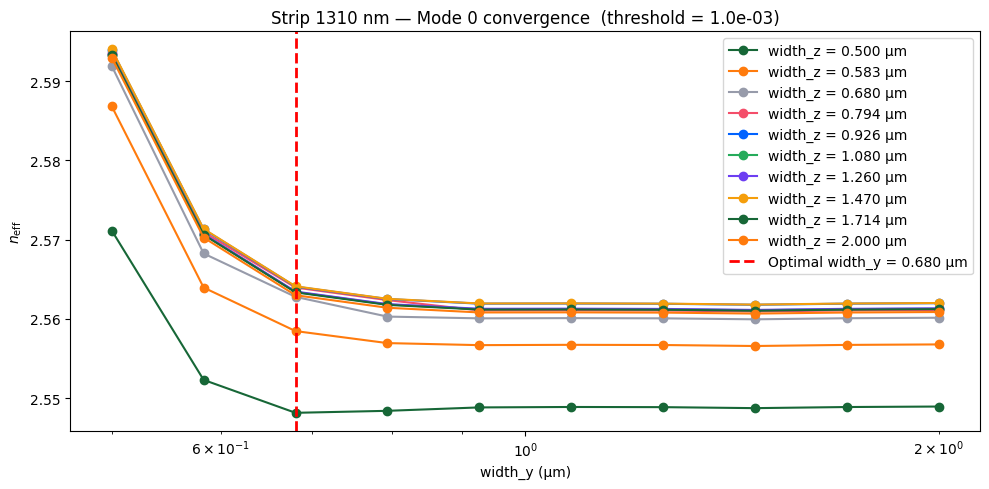


[Strip 1310 nm] Optimal boundaries:
  width_z = 0.5000 µm
  width_y = 0.6804 µm
  n_eff   = 2.548139
  Area    = 0.3402 µm²


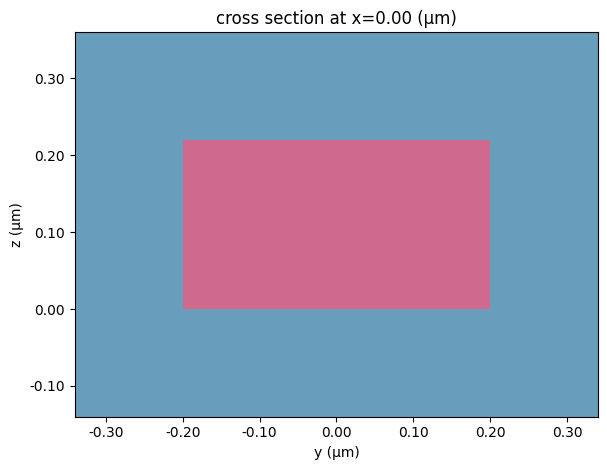

In [15]:
df_strip_1310, _, best_strip_1310 = run_port_sweep(
    "strip_1310nm",
    strip_1310nm_factory,
    1.31,
    param_width_z_strip,
    param_width_y_strip,
)
plot_sweep_results("Strip 1310 nm", df_strip_1310, best_strip_1310, strip_1310nm_factory)

## 6. Rib 1310 nm (TE)

Single-mode rib waveguide at 1310 nm. Same sweep ranges as rib 1550 nm.

18:59:21 BST Maximum FlexCredit cost: 0.377 for the whole batch.

19:01:36 BST Maximum FlexCredit cost: 0.377 for the whole batch.

[rib_1310nm_TE] Estimated cost: 0.3769 FlexCredits


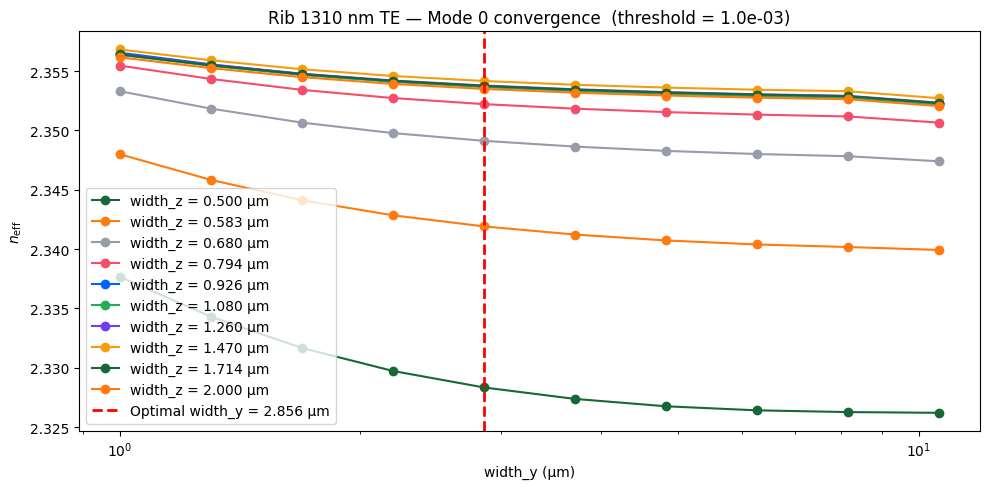


[Rib 1310 nm TE] Optimal boundaries:
  width_z = 0.5000 µm
  width_y = 2.8556 µm
  n_eff   = 2.328344
  Area    = 1.4278 µm²


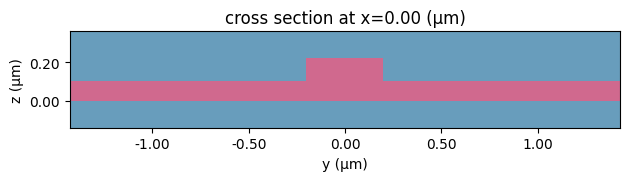

In [16]:
df_rib_1310_TE, _, best_rib_1310_TE = run_port_sweep(
    "rib_1310nm_TE",
    rib_1310nm_TE_factory,
    1.31,
    param_width_z_rib,
    param_width_y_rib,
)
plot_sweep_results("Rib 1310 nm TE", df_rib_1310_TE, best_rib_1310_TE, rib_1310nm_TE_factory)

## 7. Rib 1550 nm (TE)

Single-mode rib waveguide at 1550 nm. The slab (≈ 10.45 µm wide) requires a significantly wider `width_y` sweep than the strip ports.

19:14:56 BST Maximum FlexCredit cost: 0.374 for the whole batch.

19:17:02 BST Maximum FlexCredit cost: 0.374 for the whole batch.

[rib_1550nm_TE] Estimated cost: 0.3737 FlexCredits


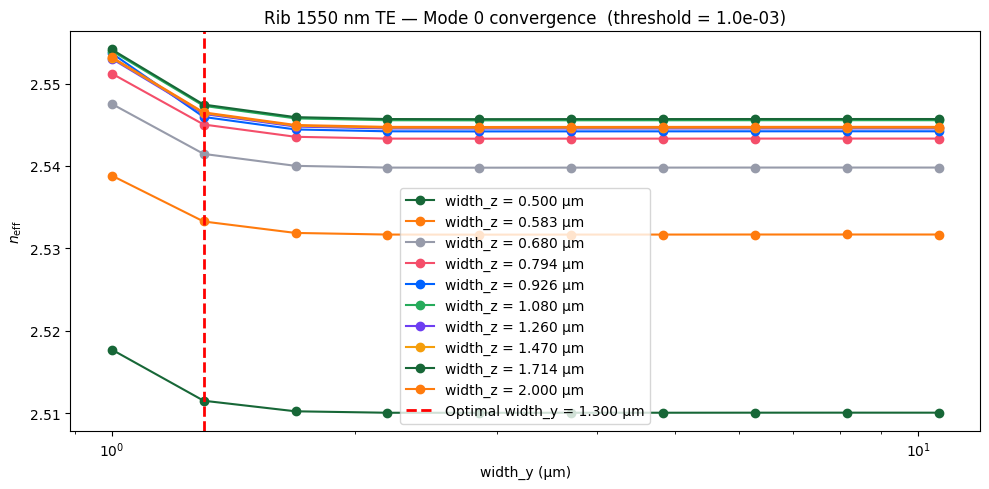


[Rib 1550 nm TE] Optimal boundaries:
  width_z = 0.5000 µm
  width_y = 1.2999 µm
  n_eff   = 2.511492
  Area    = 0.6500 µm²


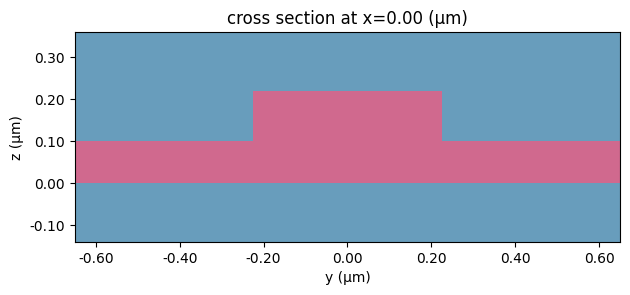

In [17]:
df_rib_1550_TE, _, best_rib_1550_TE = run_port_sweep(
    "rib_1550nm_TE",
    rib_1550nm_TE_factory,
    1.55,
    param_width_z_rib,
    param_width_y_rib,
)
plot_sweep_results("Rib 1550 nm TE", df_rib_1550_TE, best_rib_1550_TE, rib_1550nm_TE_factory)

## 8. Optimal port specs — JSON export

Collect the optimal `(limits_zmin, limits_zmax, width)` for all four ports and write them to `data/optimal_port_specs.json`, ready to be consumed by the PDK or downstream scripts.

In [20]:
z_center = 0.11  # centre of 220 nm Si layer (µm)

optimal_specs = {}
for port_name, best in {
    "strip_1550nm": best_strip_1550,
    "strip_1310nm": best_strip_1310,
    "rib_1310nm_TE": best_rib_1310_TE,
    "rib_1550nm_TE": best_rib_1550_TE,
}.items():
    width_z = float(best["width_z"])
    width_y = float(best["width_y"])
    optimal_specs[port_name] = {
        "limits_zmin": round(z_center - width_z / 2, 6),
        "limits_zmax": round(z_center + width_z / 2, 6),
        "width": round(width_y, 6),
    }

json_path = "outputs/optimal_port_specs.json"
os.makedirs("outputs", exist_ok=True)
with open(json_path, "w") as f:
    json.dump(optimal_specs, f, indent=2)

print(f"Saved to {json_path}")
print(json.dumps(optimal_specs, indent=2))

Saved to outputs/optimal_port_specs.json
{
  "strip_1550nm": {
    "limits_zmin": -0.14,
    "limits_zmax": 0.36,
    "width": 0.793701
  },
  "strip_1310nm": {
    "limits_zmin": -0.14,
    "limits_zmax": 0.36,
    "width": 0.680395
  },
  "rib_1310nm_TE": {
    "limits_zmin": -0.14,
    "limits_zmax": 0.36,
    "width": 2.855561
  },
  "rib_1550nm_TE": {
    "limits_zmin": -0.14,
    "limits_zmax": 0.36,
    "width": 1.299939
  }
}
